# Milestone 1

1. Spécifications fonctionnelles · 2. Cartographie des données · 3. Analyse de la qualité des données · 4. Préparation et nettoyage

## Paramètres communs

Tous les paramètres du milestone sont définis **une seule fois** ici (`CleaningConfig`) et réutilisés par la cartographie
(partie 2), le dictionnaire (partie 3) et la préparation (partie 5) : dossier des données, date de coupure, capacités d'un camion, jours fériés.
Pour changer une règle, on modifie cette cellule et on relance le notebook.

In [1]:
from __future__ import annotations

from dataclasses import dataclass
from pathlib import Path

import holidays
import pandas as pd

@dataclass(frozen=True)
class CleaningConfig:
    """All tunable parameters of the milestone (EF12)."""

    data_dir: Path = Path("../docs")
    output_dir: Path = Path("../data")
    truck_kg: float = 24_500.0  # DQ05: a line heavier than one truck is removed
    truck_m3: float = 110.4  # truck volume capacity (cartography, informative)
    horizon_start: str = "2026-11-09"
    horizon_end: str = "2027-01-01"
    holiday_country: str = "DE"  # no reception on German public holidays
    holiday_subdiv: str | None = None  # e.g. "BY" to add regional holidays
    tail_date: str = "2027-01-01"  # DQ03: rows dated on or after this day are removed
    # DQ04: how a missing weight / volume is imputed.
    #   None -> a full truck (truck_kg / truck_m3), the most prudent choice
    #   0..1 -> that quantile of the valid values of the same couple, else of the same plant (0.5 = median)
    impute_quantile: float | None = None
    max_anticipation_days: int = 7  # RG03
    allowed_frequencies: tuple[int, ...] = (1, 2, 3, 4, 5)  # RG05, deliveries per week
    couple_key: tuple[str, ...] = ("supplier_id", "plant")  # RG01
    key_columns: tuple[str, ...] = (
        "date",
        "supplier_id",
        "material",
        "plant",
        "unloading_point",
    )

    def __post_init__(self) -> None:
        if self.impute_quantile is not None and not 0.0 <= self.impute_quantile <= 1.0:
            raise ValueError("impute_quantile must be None or between 0 and 1")


cfg = CleaningConfig()
german_holidays = holidays.country_holidays(
    cfg.holiday_country,
    subdiv=cfg.holiday_subdiv,
    years=range(pd.Timestamp(cfg.horizon_start).year, pd.Timestamp(cfg.horizon_end).year + 1),
)
horizon_holidays = sorted(
    d
    for d in german_holidays
    if pd.Timestamp(cfg.horizon_start).date() <= d <= pd.Timestamp(cfg.horizon_end).date()
)
cfg

CleaningConfig(data_dir=WindowsPath('../docs'), output_dir=WindowsPath('../data'), truck_kg=24500.0, truck_m3=110.4, horizon_start='2026-11-09', horizon_end='2027-01-01', holiday_country='DE', holiday_subdiv=None, tail_date='2027-01-01', impute_quantile=None, max_anticipation_days=7, allowed_frequencies=(1, 2, 3, 4, 5), couple_key=('supplier_id', 'plant'), key_columns=('date', 'supplier_id', 'material', 'plant', 'unloading_point'))

---

# Partie 1 - Spécifications fonctionnelles

*Source : `specs.ipynb`*

## Spécifications fonctionnelles

## 1.1 Liste des hypothèses / Réponses Client
- 7 jours d'anticipation calendaires (RG03)
- Il est préférable de rajouter des jours de livraison plutôt que de rajouter des camions
- On ne réceptionne rien le week-end ni les jours fériés allemands (précisé par le client ; calendrier national allemand, paquet `holidays`). Le 11/11 n'est pas férié en Allemagne
- L'usine est fermée les deux dernières semaines de décembre : aucun besoin du 21 au 31/12
- Poids ou volume manquant : par défaut on suppose un camion plein (24,5 t, 110,4 m³), pour surestimer plutôt que sous-estimer la charge ; la règle est réglable (`impute_quantile`)

## 1.2 Questions
- On receptionne comment le 01 janvier si l'entreprise est en congés. Les congés font il parti des 7 jours d'anticipation?

## 1.3 Objectifs métier
- Réduire le nombre de livraisons.
- Mieux remplir les camions.
- Répartir les livraisons sur la semaine dans chaque usine.
- Chiffrer l'économie, couple par couple, sans compromettre l'approvisionnement.

## 1.4 Périmètre
Le périmètre couvre les besoins du 09/11/2026 au 18/12/2026 : 93 fournisseurs,
4 usines et 49 quais de déchargement, transportés via un point de consolidation
unique. Le 01/01/2027 (besoins cumulés au-delà de l'horizon) est exclu, voir DQ05.

## 1.5 Acteurs et utilisateurs
L'utilisateur principal est l'équipe logistique, qui applique les profils recommandés ;
les autres acteurs subissent ou valident le résultat.

| Acteur | Rôle |
| :--- | :--- |
| **Équipe logistique / approvisionnement** | Utilisateur principal : fixe les profils et pilote le planning |
| **Usines et quais de déchargement** | Réceptionnent les pièces |
| **Fournisseurs** | Expédient selon le programme reçu |
| **Transporteur** | Achemine via le point de consolidation, facture par envoi |

## 1.6 Règles de gestion

| ID | Règle | Formalisation |
| :--- | :--- | :--- |
| **RG01** | La consolidation se fait par couple fournisseur × usine | Un camion ne transporte qu'un fournisseur et ne dessert qu'une usine ; il peut desservir plusieurs quais de cette usine |
| **RG02** | Un besoin n'est jamais livré en retard | Jour de livraison ≤ date du besoin |
| **RG03** | Anticipation limitée à 7 jours | Date du besoin − jour de livraison ≤ 7 jours calendaires |
| **RG04** | Capacité d'un camion | Poids ≤ 24 500 kg et volume ≤ 110,4 m³ ; le camion est plein dès qu'une limite est atteinte |
| **RG05** | Profil de livraison | Fréquence de 1, 2, 3, 4 ou 5 livraisons par semaine, sur des jours ouvrés fixes |
| **RG06** | Couverture d'un jour de livraison | Un jour de livraison couvre les besoins jusqu'au jour de livraison suivant, exclu |
| **RG07** | Choix de la fréquence | La plus haute qui respecte RG03 et RG04, chaque livraison tenant dans un camion ; si 5 / semaine ne suffit pas, on ajoute des camions |
| **RG08** | Exhaustivité | Pour chaque material, quantité livrée = quantité demandée (limite connue : la ligne plus lourde qu'un camion, 26,9 t, est retirée en DQ07 et n'est donc pas livrée) |
| **RG09** | Lissage | Les jours de livraison sont répartis entre les couples d'une même usine ; les profils 1 / semaine ne tombent pas tous le même jour |
| **RG10** | Jour non livrable | Un jour de livraison férié est avancé au jour ouvré précédent, dans la limite de RG03 |
| **RG11** | Prix d'un envoi | Tranches lues en « jusqu'à » (121 km → tranche 125 km) ; un envoi = un camion ; au-delà de 4 000 kg, tarif forfaitaire (prix constant jusqu'à 24,5 t) |
| **RG12** | Situation de référence | Une livraison par couple et par jour de besoin, chiffrée avec la même grille |

Le prix d'un envoi (RG11) se calcule ainsi :
Prix = Coût grille(distance, poids) × (1 + 2,3923) × 1,1943

## 1.7 Exigences fonctionnelles

| ID | Exigence |
| :--- | :--- |
| **EF01** | Importer un planning, les distances et la grille tarifaire, avec lecture automatique du PDF |
| **EF02** | Contrôler la qualité des données et produire un registre des anomalies (gravité, règle appliquée) |
| **EF03** | Compléter les données manquantes selon des règles paramétrables et tracer chaque imputation |
| **EF04** | Mesurer la situation actuelle : livraisons, remplissage et coût par couple et par usine |
| **EF05** | Déterminer le profil de livraison de chaque couple selon RG07 |
| **EF06** | Répartir les jours de livraison entre les couples d'une même usine (RG09) |
| **EF07** | Affecter chaque ligne de besoin à un jour de livraison |
| **EF08** | Chiffrer le coût avant / après et le saving par couple, par usine et au total |
| **EF09** | Vérifier automatiquement RG02, RG03, RG04 et RG08 et signaler toute violation |
| **EF10** | Justifier chaque recommandation : pourquoi cette fréquence, quels besoins dans quel camion |
| **EF11** | Exporter les sorties 1, 2 et 3 en CSV |
| **EF12** | Modifier les paramètres (capacités, anticipation, diesel surcharge, margin) sans toucher au code |
| **EF13** | Consulter et filtrer les résultats dans un tableau de bord, par usine et par fournisseur |

### 1.7.1 Les indicateurs de pilotage

| Indicateur | Définition | Sens souhaité |
|---|---|---|
| Nombre de livraisons | Nombre de couples × jour livrés (et de camions) sur l'horizon | ↓ |
| Taux de remplissage | Poids (et volume) chargé / capacité, par camion | ↑ |
| Coût de transport | Σ prix des envois (*rate sheet*) | ↓ |
| *Saving* | Coût actuel − coût après consolidation (EUR, %) | ↑ |
| Anticipation moyenne | Nombre moyen de jours d'avance d'un besoin livré (impact stock usine) | à surveiller |
| Lissage | Répartition des livraisons par jour de la semaine et par usine | équilibré |
| Respect des contraintes | Nombre de violations : retard, anticipation > 7 jours, capacité dépassée, quantité non livrée | = 0 |

## 1.8 Livrables:
- Sortie 1 : un profil pour chaque couple
- Sortie 2 : les materials groupés dans chaque camion
- Sortie 3 : saving potentiel par couple

## 1.9 Analyse de données
- KPI accuracy : part des lignes du planning conservées sans modification avant l'optimisation, en fonction du nombre de transformations (calculé en 5.6)


---

# Partie 2 - Cartographie des données

*Source : `cartographie.ipynb`*

## Cartographie des données

2.1 Modèle de données · 2.2 Grain des tables · 2.3 Lignage des colonnes · 2.4 Intégrité des liens · 2.5 Flux de traitement

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

pd.set_option("display.max_colwidth", None)

schedule_brut = pd.read_csv(cfg.data_dir / "released_schedule.csv", encoding="utf-8-sig", parse_dates=["date"])
schedule = schedule_brut[schedule_brut["date"] < cfg.tail_date]  # dates >= tail_date écartées (cumul de fin d'horizon)
besoins = schedule[schedule["schedule_quantity"] > 0]
distances = pd.read_csv(cfg.data_dir / "distances.csv", encoding="utf-8-sig")
grille = pd.read_csv(cfg.data_dir / "rate_sheet.csv", dtype={"km_up_to": str}).set_index("km_up_to")

## 2.1 Modèle de données
Chaque boîte est une entité, avec sa clé et son effectif. Un trait plein = lien par clé (1 → N). Un trait vert pointillé = lecture de la grille par intervalle.

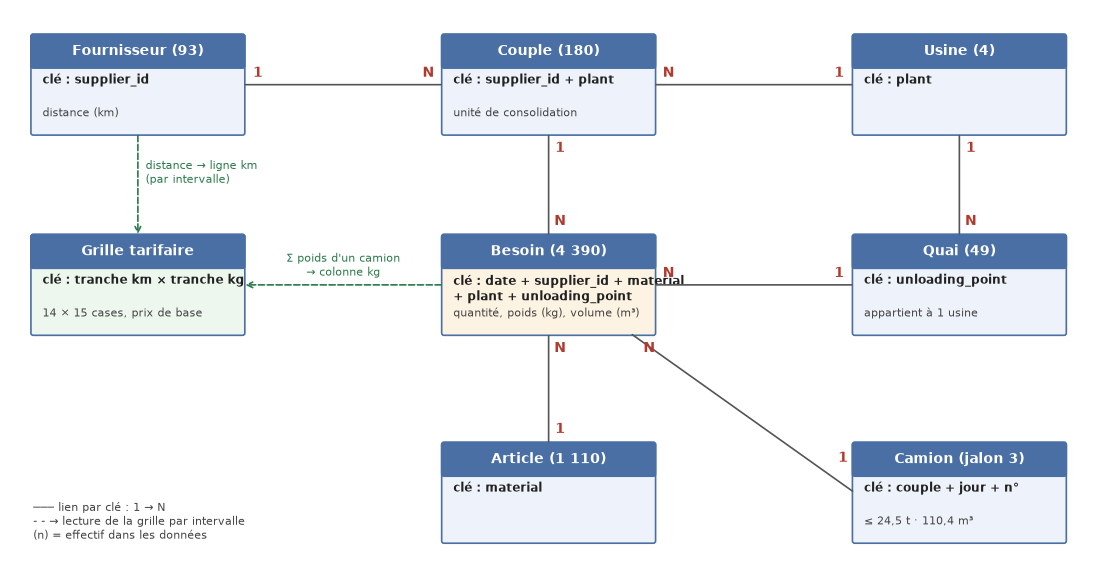

In [3]:
n = {
    "Fournisseur": besoins["supplier_id"].nunique(), "Usine": besoins["plant"].nunique(),
    "Quai": besoins["unloading_point"].nunique(), "Article": besoins["material"].nunique(),
    "Besoin": len(besoins), "Couple": besoins.groupby(["supplier_id", "plant"]).ngroups,
}
fmt = lambda x: f"{x:,}".replace(",", " ")

fig, ax = plt.subplots(figsize=(14, 7.2))
ax.set_xlim(0, 14); ax.set_ylim(0, 7.2); ax.axis("off")
W, H = 2.7, 1.25
P = {"Fournisseur": (0.3, 5.6), "Couple": (5.6, 5.6), "Usine": (10.9, 5.6),
     "Grille": (0.3, 3.0), "Besoin": (5.6, 3.0), "Quai": (10.9, 3.0),
     "Article": (5.6, 0.3), "Camion": (10.9, 0.3)}

def entite(cle_pos, titre, cle, attributs="", couleur="#eef3fb"):
    x, y = P[cle_pos]
    ax.add_patch(FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0.03", fc=couleur, ec="#4a6fa5", lw=1.2))
    ax.add_patch(FancyBboxPatch((x, y + H - 0.38), W, 0.38, boxstyle="round,pad=0.03", fc="#4a6fa5", ec="#4a6fa5", lw=1.2))
    ax.text(x + W / 2, y + H - 0.19, titre, ha="center", va="center", fontsize=10, color="white", weight="bold")
    ax.text(x + 0.12, y + H - 0.48, cle, fontsize=8.5, va="top", weight="bold", color="#222")
    ax.text(x + 0.12, y + 0.18, attributs, fontsize=8, va="bottom", color="#444")

def lien(a, b, pos_1, pos_n):
    ax.annotate("", b, a, arrowprops=dict(arrowstyle="-", color="#555", lw=1.2))
    ax.text(*pos_1, "1", fontsize=10, weight="bold", color="#b03a2e", ha="center", va="center")
    ax.text(*pos_n, "N", fontsize=10, weight="bold", color="#b03a2e", ha="center", va="center")

entite("Fournisseur", f"Fournisseur ({n['Fournisseur']})", "clé : supplier_id", "distance (km)")
entite("Couple", f"Couple ({n['Couple']})", "clé : supplier_id + plant", "unité de consolidation")
entite("Usine", f"Usine ({n['Usine']})", "clé : plant")
entite("Besoin", f"Besoin ({fmt(n['Besoin'])})", "clé : date + supplier_id + material\n+ plant + unloading_point",
       "quantité, poids (kg), volume (m³)", couleur="#fdf3e3")
entite("Quai", f"Quai ({n['Quai']})", "clé : unloading_point", "appartient à 1 usine")
entite("Article", f"Article ({fmt(n['Article'])})", "clé : material")
entite("Camion", "Camion (jalon 3)", "clé : couple + jour + n°", "≤ 24,5 t · 110,4 m³")
entite("Grille", "Grille tarifaire", "clé : tranche km × tranche kg", "14 × 15 cases, prix de base", couleur="#eef7ee")

cx = lambda k: P[k][0] + W / 2
cy = lambda k: P[k][1] + H / 2
haut, bas, gauche, droite = (lambda k: P[k][1] + H), (lambda k: P[k][1]), (lambda k: P[k][0]), (lambda k: P[k][0] + W)
lien((droite("Fournisseur"), cy("Fournisseur")), (gauche("Couple"), cy("Couple")),
     (droite("Fournisseur") + 0.2, cy("Fournisseur") + 0.15), (gauche("Couple") - 0.2, cy("Couple") + 0.15))
lien((gauche("Usine"), cy("Usine")), (droite("Couple"), cy("Couple")),
     (gauche("Usine") - 0.2, cy("Usine") + 0.15), (droite("Couple") + 0.2, cy("Couple") + 0.15))
lien((cx("Couple"), bas("Couple")), (cx("Besoin"), haut("Besoin")),
     (cx("Couple") + 0.15, bas("Couple") - 0.2), (cx("Besoin") + 0.15, haut("Besoin") + 0.2))
lien((cx("Usine"), bas("Usine")), (cx("Quai"), haut("Quai")),
     (cx("Usine") + 0.15, bas("Usine") - 0.2), (cx("Quai") + 0.15, haut("Quai") + 0.2))
lien((gauche("Quai"), cy("Quai")), (droite("Besoin"), cy("Besoin")),
     (gauche("Quai") - 0.2, cy("Quai") + 0.15), (droite("Besoin") + 0.2, cy("Besoin") + 0.15))
lien((cx("Article"), haut("Article")), (cx("Besoin"), bas("Besoin")),
     (cx("Article") + 0.15, haut("Article") + 0.2), (cx("Besoin") + 0.15, bas("Besoin") - 0.2))
lien((gauche("Camion"), cy("Camion")), (droite("Besoin") - 0.3, bas("Besoin")),
     (gauche("Camion") - 0.15, cy("Camion") + 0.45), (droite("Besoin") - 0.05, bas("Besoin") - 0.2))

vert = dict(arrowstyle="->", color="#2b7a4b", lw=1.2, ls="--")
ax.annotate("", (cx("Grille"), haut("Grille")), (cx("Fournisseur"), bas("Fournisseur")), arrowprops=vert)
ax.text(cx("Grille") + 0.1, 4.95, "distance → ligne km\n(par intervalle)", fontsize=8, color="#2b7a4b")
ax.annotate("", (droite("Grille"), cy("Grille")), (gauche("Besoin"), cy("Besoin")), arrowprops=vert)
ax.text((droite("Grille") + gauche("Besoin")) / 2, cy("Grille") + 0.12, "Σ poids d'un camion\n→ colonne kg",
        fontsize=8, color="#2b7a4b", ha="center")
ax.text(0.3, 0.55, "─── lien par clé : 1 → N\n- - → lecture de la grille par intervalle\n(n) = effectif dans les données",
        fontsize=8, color="#444", va="center")
plt.show()

**Lecture.** Le **Besoin** est au centre : chaque ligne relie un fournisseur, un article, un quai (donc une usine) et un jour. Les besoins d'un même **couple** fournisseur × usine sont consolidés ensemble. Les besoins d'un couple sont regroupés dans des **camions** (≤ 24,5 t et 110,4 m³) : ce sont eux qui donnent le profil de livraison et le coût. Le prix se lit dans la grille par **intervalles** : la ligne vient de la distance du fournisseur, la colonne du poids total du camion, donc après regroupement.

## 2.2 Grain des tables
Ce que représente une ligne à chaque étape, et combien il y en a.

In [4]:
feries = pd.to_datetime(list(german_holidays))
# Previous business day: skips weekends AND German public holidays (same calendar as the shared config)
jour_ouvre = pd.offsets.CustomBusinessDay(holidays=list(german_holidays))
jour_livraison = besoins["date"].where(~besoins["date"].isin(feries), besoins["date"] - jour_ouvre)
livraisons_actuelles = besoins.assign(date=jour_livraison).groupby(["supplier_id", "plant", "date"]).ngroups

pd.DataFrame([
    ("1. Planning brut", "fournisseur × article × usine × quai × date", len(schedule_brut)),
    (f"2. Avant le {pd.Timestamp(cfg.tail_date):%d/%m/%Y}", "idem", len(schedule)),
    ("3. Besoins (quantité > 0)", "idem", len(besoins)),
    ("4. Livraisons actuelles", "couple × jour (jour férié → veille)", livraisons_actuelles),
    ("5. Couples", "fournisseur × usine", besoins.groupby(["supplier_id", "plant"]).ngroups),
    ("6. Camions", f"un camion ≤ {cfg.truck_kg / 1000:.1f} t et {cfg.truck_m3} m³".replace(".", ","), "algorithme (jalon 3)"),
    ("Sortie 1", "couple : profil de livraison", besoins.groupby(["supplier_id", "plant"]).ngroups),
    ("Sortie 2", "camion × article × quai", "algorithme (jalon 3)"),
    ("Sortie 3", "couple, puis total : économie", "algorithme (jalon 3)"),
], columns=["étape", "une ligne =", "lignes"]).set_index("étape")

C:\Users\houeg\AppData\Local\Temp\ipykernel_22556\3068766111.py:4: PerformanceWarning: Non-vectorized DateOffset being applied to Series or DatetimeIndex.
  jour_livraison = besoins["date"].where(~besoins["date"].isin(feries), besoins["date"] - jour_ouvre)


,une ligne =,lignes
étape,,
1. Planning brut,fournisseur × article × usine × quai × date,5728
2. Avant le 01/01/2027,idem,5308
3. Besoins (quantité > 0),idem,4390
4. Livraisons actuelles,couple × jour (jour férié → veille),1665
5. Couples,fournisseur × usine,180
6. Camions,"un camion ≤ 24,5 t et 110,4 m³",algorithme (jalon 3)
Sortie 1,couple : profil de livraison,180
Sortie 2,camion × article × quai,algorithme (jalon 3)
Sortie 3,"couple, puis total : économie",algorithme (jalon 3)


## 2.3 Lignage des colonnes
Ce que devient chaque colonne source, jusqu'aux sorties.

| Colonne source | Transformation | Sert à | Sortie |
|---|---|---|---|
| `supplier_id` + `plant` | regroupement | couple : profil, camions | 1, 2, 3 |
| `date` | jour férié → veille ; dernier jour du profil ≤ date | date de livraison ; anticipation ≤ 7 jours | 1, 2 |
| `schedule_quantity` | filtre > 0 | quantité de chaque article dans le camion | 2 |
| `weight` | Σ par camion | capacité 24,5 t ; colonne kg de la grille | 2, 3 |
| `volume` | Σ par camion | capacité 110,4 m³ | 2 |
| `material`, `unloading_point` | conservés tels quels | contenu et quais desservis par le camion | 2 |
| `distance` | jointure sur `supplier_id` | ligne km de la grille | 3 |
| grille, marge, diesel | lecture par intervalles × (1 + marge) × diesel | coût d'un camion | 3 |
| `transmission_date`, `version_date` | non utilisées | – | – |

## 2.4 Intégrité des liens
Chaque lien du modèle est vérifié sur les données.

In [5]:
fournisseurs = besoins["supplier_id"].drop_duplicates()
controles = [
    ("Besoin → Fournisseur : fournisseurs trouvés dans distances.csv",
     f"{fournisseurs.isin(distances['supplier_id']).sum()} / {len(fournisseurs)}"),
    ("Fournisseur → distance : distance renseignée",
     f"{fournisseurs.isin(distances.dropna()['supplier_id']).sum()} / {len(fournisseurs)}"),
    ("distances.csv : fournisseurs sans aucun besoin", int((~distances["supplier_id"].isin(fournisseurs)).sum())),
    ("Quai → Usine : usines max par quai", int(besoins.groupby("unloading_point")["plant"].nunique().max())),
    ("Volume : valeurs différentes max par article × quai",
     int(besoins.dropna(subset=["volume"]).groupby(["material", "unloading_point"])["volume"].nunique().max())),
    ("Fournisseurs livrant plusieurs usines",
     f"{int((besoins.groupby('supplier_id')['plant'].nunique() > 1).sum())} / {len(fournisseurs)}"),
    ("Articles livrés à plusieurs usines",
     f"{int((besoins.groupby('material')['plant'].nunique() > 1).sum())} / {besoins['material'].nunique()}"),
    ("Clé du besoin unique (doublons)", int(besoins.duplicated(list(cfg.key_columns)).sum())),
]
pd.DataFrame(controles, columns=["contrôle", "résultat"]).set_index("contrôle")

,résultat
contrôle,
Besoin → Fournisseur : fournisseurs trouvés dans distances.csv,93 / 93
Fournisseur → distance : distance renseignée,92 / 93
distances.csv : fournisseurs sans aucun besoin,63
Quai → Usine : usines max par quai,1
Volume : valeurs différentes max par article × quai,1
Fournisseurs livrant plusieurs usines,52 / 93
Articles livrés à plusieurs usines,95 / 1110
Clé du besoin unique (doublons),0


## 2.5 Flux de traitement
De la donnée brute aux trois sorties. Les étapes en bleu sont réalisées dans ce milestone, celles en orange le seront au jalon 3.

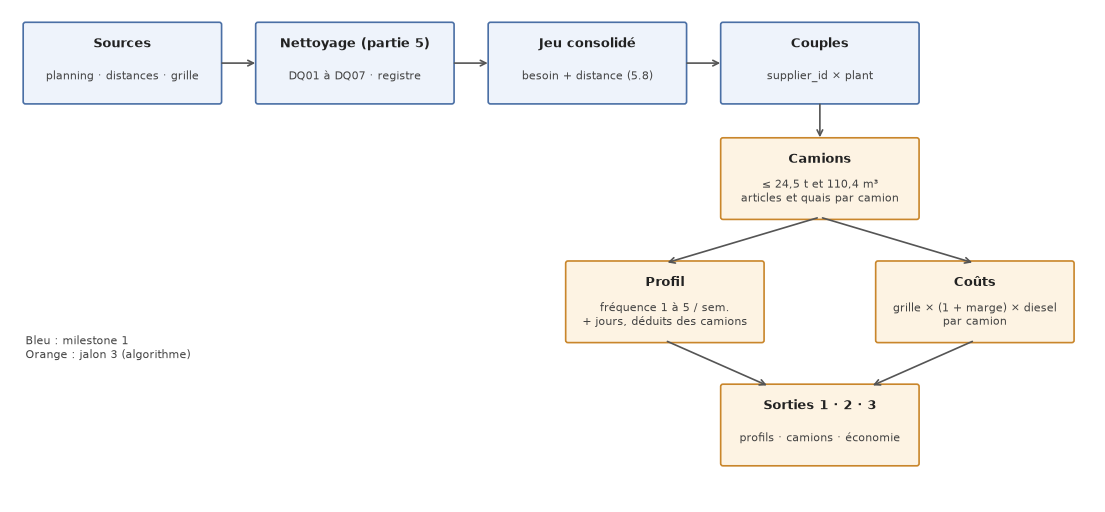

In [6]:
fig, ax = plt.subplots(figsize=(14, 6.4))
ax.set_xlim(0, 14)
ax.set_ylim(0, 6.4)
ax.axis("off")
BW, BH = 2.5, 1.0


def etape(x, y, titre, detail, fait=True):
    couleur, bord = ("#eef3fb", "#4a6fa5") if fait else ("#fdf3e3", "#c9862b")
    ax.add_patch(FancyBboxPatch((x, y), BW, BH, boxstyle="round,pad=0.03", fc=couleur, ec=bord, lw=1.2))
    ax.text(x + BW / 2, y + BH - 0.25, titre, ha="center", va="center", fontsize=9.5, weight="bold", color="#222")
    ax.text(x + BW / 2, y + 0.33, detail, ha="center", va="center", fontsize=8, color="#444")


def fleche(x1, y1, x2, y2):
    ax.annotate("", (x2, y2), (x1, y1), arrowprops=dict(arrowstyle="->", color="#555", lw=1.2))


# Row 1: data preparation (this milestone)
top = 5.2
etape(0.2, top, "Sources", "planning · distances · grille")
etape(3.2, top, "Nettoyage (partie 5)", "DQ01 à DQ07 · registre")
etape(6.2, top, "Jeu consolidé", "besoin + distance (5.8)")
etape(9.2, top, "Couples", f"{cfg.couple_key[0]} × {cfg.couple_key[1]}")
# Trucks give both the profile and the costs
etape(9.2, 3.7, "Camions", "≤ 24,5 t et 110,4 m³\narticles et quais par camion", fait=False)
etape(7.2, 2.1, "Profil", "fréquence 1 à 5 / sem.\n+ jours, déduits des camions", fait=False)
etape(11.2, 2.1, "Coûts", "grille × (1 + marge) × diesel\npar camion", fait=False)
etape(9.2, 0.5, "Sorties 1 · 2 · 3", "profils · camions · économie", fait=False)
for a, b in [
    ((2.7, top + 0.5), (3.2, top + 0.5)),
    ((5.7, top + 0.5), (6.2, top + 0.5)),
    ((8.7, top + 0.5), (9.2, top + 0.5)),
    ((10.45, top), (10.45, 4.7)),
    ((10.45, 3.7), (8.45, 3.1)),
    ((10.45, 3.7), (12.45, 3.1)),
    ((8.45, 2.1), (9.8, 1.5)),
    ((12.45, 2.1), (11.1, 1.5)),
]:
    fleche(*a, *b)
ax.text(0.2, 2.0, "Bleu : milestone 1\nOrange : jalon 3 (algorithme)", fontsize=8, color="#444", va="center")
plt.show()

---

# Partie 3 - Dictionnaire des données

*Source : `dictionnaire.ipynb`*

## Dictionnaire des données 
3.1 Inventaire · 3.2 Planning · 3.3 Distances · 3.4 Grille tarifaire · 3.5 Données calculées

In [7]:
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", None)
SCHEDULE, DISTANCES, RATES = cfg.data_dir / "released_schedule.csv", cfg.data_dir / "distances.csv", cfg.data_dir / "rate_sheet.csv"

# Les CSV commencent par un BOM : "utf-8-sig" le retire.
schedule = pd.read_csv(SCHEDULE, encoding="utf-8-sig", parse_dates=["date", "transmission_date", "version_date"])
schedule = schedule[schedule["date"] < cfg.tail_date]  # dates >= tail_date écartées (cumul de fin d'horizon)
distances = pd.read_csv(DISTANCES, encoding="utf-8-sig")
grille = pd.read_csv(RATES, dtype={"km_up_to": str}).set_index("km_up_to")  # grille du PDF, transcrite en CSV
besoins = schedule[schedule["schedule_quantity"] > 0]  # besoins réels (Partie 5, DQ01)
CLE_SCHEDULE = list(cfg.key_columns)

## 3.1 Inventaire des sources

| | `released_schedule.csv` | `distances.csv` | `rate_sheet.pdf` |
|---|---|---|---|
| Rôle | Besoin : quoi, quand, où, combien | Distance → ligne de la grille | Prix d'un envoi (= un camion) ; transcrit dans `rate_sheet.csv` |
| Une ligne = | fournisseur × article × usine × quai × date | fournisseur | tranche de km × 15 tranches de kg |
| Clé | 5 colonnes de `CLE_SCHEDULE` | `supplier_id` | (distance, poids) |
| Origine, mise à jour | *programme usine, à chaque version* | *référentiel, rarement* | *contrat transporteur, à chaque renégociation* |

*Italique = déduction à confirmer auprès du client.*

In [8]:
def a_un_bom(chemin):
    with open(chemin, "rb") as f:
        return f.read(3) == b"\xef\xbb\xbf"

pd.DataFrame({
    "released_schedule.csv": [len(schedule), schedule.shape[1], a_un_bom(SCHEDULE),
                              f"{besoins['date'].min():%d/%m/%Y} → {besoins['date'].max():%d/%m/%Y}"],
    "distances.csv": [len(distances), distances.shape[1], a_un_bom(DISTANCES), "non datée"],
}, index=["lignes", "colonnes", "BOM", "période des besoins"])

,released_schedule.csv,distances.csv
lignes,5308,156
colonnes,10,2
BOM,True,True
période des besoins,09/11/2026 → 18/12/2026,non datée


## 3.2 Dictionnaire de `released_schedule.csv`
Statistiques sur les besoins réels (quantité > 0).

In [9]:
definitions = pd.DataFrame([
    ("date", "jour", "Jour où la pièce doit être à l'usine", "Jamais le week-end ni un jour férié allemand ; aucun besoin du 21 au 31/12 (usine fermée)"),
    ("supplier_id", "–", "Fournisseur", "Clé vers distances.csv"),
    ("material", "–", "Référence de la pièce", "Parfois livrée à plusieurs usines"),
    ("plant", "–", "Usine de destination", "Fournisseur × usine = couple, unité de consolidation"),
    ("unloading_point", "–", "Quai de déchargement", "1 quai = 1 usine ; plusieurs quais par camion (confirmé)"),
    ("schedule_quantity", "pièces", "Pièces à livrer", "Entiers ; 0 = pas de besoin (Partie 5, DQ01)"),
    ("weight", "kg", "Poids de la ligne, emballage compris (confirmé)", "Chaque ligne a son propre emballage : part fixe + poids par pièce (3.2.1) ; manquants (Partie 4, 4.6 et Partie 5, DQ04)"),
    ("volume", "m³", "Volume du conteneur de la ligne (confirmé)", "Fixe par article × quai, indépendant de la quantité (3.2.1)"),
    ("transmission_date", "jour", "Date d'envoi du programme au fournisseur (définition du cadrage)", "Non utilisée"),
    ("version_date", "jour", "Version du programme", "Une seule version ; non utilisée"),
], columns=["colonne", "unité", "description", "remarque"]).set_index("colonne")

stats = pd.DataFrame({
    "manquants (toutes lignes)": schedule.isna().sum(),
    "manquants (besoins)": besoins.isna().sum(),
    "distinctes": besoins.nunique(),
    "min": besoins.min(numeric_only=False),
    "max": besoins.max(numeric_only=False),
})
for c in ["min", "max"]:
    stats[c] = stats[c].map(lambda v: f"{v:%d/%m/%Y}" if isinstance(v, pd.Timestamp) else v)
definitions.join(stats)

,unité,description,remarque,manquants (toutes lignes),manquants (besoins),distinctes,min,max
colonne,,,,,,,,
date,jour,Jour où la pièce doit être à l'usine,Jamais le week-end ni un jour férié allemand ; aucun besoin du 21 au 31/12 (usine fermée),0,0,30,09/11/2026,18/12/2026
supplier_id,–,Fournisseur,Clé vers distances.csv,0,0,93,SUP_00001,SUP_00156
material,–,Référence de la pièce,Parfois livrée à plusieurs usines,0,0,1110,MAT_000001,MAT_001229
plant,–,Usine de destination,"Fournisseur × usine = couple, unité de consolidation",0,0,4,PLT_001,PLT_004
unloading_point,–,Quai de déchargement,1 quai = 1 usine ; plusieurs quais par camion (confirmé),0,0,49,ULP_0001,ULP_0050
schedule_quantity,pièces,Pièces à livrer,"Entiers ; 0 = pas de besoin (Partie 5, DQ01)",0,0,367,1.0,100000.0
weight,kg,"Poids de la ligne, emballage compris (confirmé)","Chaque ligne a son propre emballage : part fixe + poids par pièce (3.2.1) ; manquants (Partie 4, 4.6 et Partie 5, DQ04)",163,134,1546,0.77,26905.2
volume,m³,Volume du conteneur de la ligne (confirmé),"Fixe par article × quai, indépendant de la quantité (3.2.1)",143,116,59,0.00882,5.808
transmission_date,jour,Date d'envoi du programme au fournisseur (définition du cadrage),Non utilisée,0,0,12,02/02/2026,07/11/2026


## 3.3 Dictionnaire de `distances.csv`

In [12]:
dist_planning = distances[distances["supplier_id"].isin(besoins["supplier_id"])]

pd.DataFrame([
    ("supplier_id", "–", "Fournisseur", "Clé unique"),
    ("distance", "km", "Distance fournisseur → point de consolidation (définition du cadrage)",
     "Entiers ; même distance pour toutes les usines d'un fournisseur ; manquants : Partie 5, DQ07"),
], columns=["colonne", "unité", "description", "remarque"]).set_index("colonne").join(pd.DataFrame({
    "manquants (fichier)": distances.isna().sum(),
    "manquants (fournisseurs du planning)": dist_planning.isna().sum(),
    "distinctes": distances.nunique(),
    "min": distances.min(),
    "max": distances.max(),
}))

,unité,description,remarque,manquants (fichier),manquants (fournisseurs du planning),distinctes,min,max
colonne,,,,,,,,
supplier_id,–,Fournisseur,Clé unique,0,0,156,SUP_00001,SUP_00156
distance,km,Distance fournisseur → point de consolidation (définition du cadrage),"Entiers ; même distance pour toutes les usines d'un fournisseur ; manquants : Partie 5, DQ07",11,1,85,6.0,149.0


## 3.4 Dictionnaire de la grille tarifaire (`rate_sheet.pdf`)
Prix d'un envoi (= un camion) = coût de base × (1 + marge) × surcharge diesel. Lecture, contrôles et fonction `prix` : Partie 4, 4.4.

In [13]:
pd.DataFrame([
    ("ligne", "km", "Tranche de distance, borne haute incluse (47 km → ligne 50)", f"{len(grille)} tranches, de {grille.index[0]} à {grille.index[-1]}"),
    ("colonne", "kg", "Tranche de poids d'un camion, borne haute incluse (316 kg → colonne 400)", f"{grille.shape[1]} tranches, de {grille.columns[0]} à {grille.columns[-1]}"),
    ("case", "EUR", "Coût de base d'un envoi", f"{grille.values.min()} à {grille.values.max()}"),
    ("marge", "%", "Marge appliquée au coût de base (PDF)", "239,23 %"),
    ("diesel", "facteur", "Surcharge carburant (PDF)", "1,1943"),
    ("validité", "date", "Date d'entrée en vigueur (PDF)", "01/08/2026"),
], columns=["élément", "unité", "description", "valeur"]).set_index("élément")

,unité,description,valeur
élément,,,
ligne,km,"Tranche de distance, borne haute incluse (47 km → ligne 50)","14 tranches, de 30 à >650"
colonne,kg,"Tranche de poids d'un camion, borne haute incluse (316 kg → colonne 400)","15 tranches, de 50 à >4000"
case,EUR,Coût de base d'un envoi,4.75 à 325.25
marge,%,Marge appliquée au coût de base (PDF),"239,23 %"
diesel,facteur,Surcharge carburant (PDF),"1,1943"
validité,date,Date d'entrée en vigueur (PDF),01/08/2026


Au-delà de 4 000 kg, le prix ne bouge plus jusqu'à 24,5 t (confirmé par le métier).

## 3.5 Données calculées

| Donnée | Formule | Unité | Calculée en |
|---|---|---|---|
| couple | `supplier_id` + `plant` | – | Partie 2, 2.2 |
| livraison actuelle | couple × date du besoin (jour férié allemand → veille ouvrée) | – | Partie 2, 2.2 |
| poids / volume d'une livraison ou d'un camion | Σ `weight` / Σ `volume` des lignes regroupées | kg / m³ | jalon 3 |
| nombre de camions | ⌈ max(poids / 24 500 ; volume / 110,4) ⌉ | camions | jalon 3 |
| remplissage | poids / (camions × 24 500), idem en volume | % | jalon 3 |
| coût d'un envoi (= un camion) | case(ligne km ≥ distance, colonne kg ≥ poids) × (1 + marge) × diesel | € | Partie 4, 4.4 (fonction `prix`) |
| profil | fréquence (1, 2, 3, 4 ou 5 / semaine) + jours, identique chaque semaine | – | algorithme |
| date de livraison | dernier jour ouvré du profil ≤ date du besoin, écart ≤ 7 jours | date | algorithme |
| anticipation | date du besoin − date de livraison | jours | algorithme |
| économie | coût avant − coût après (et en % du coût avant) | € | algorithme |

 Chaque ligne a son propre emballage et son conteneur (confirmé) : la somme des poids et des volumes est la vraie charge d'un camion. Le grain de ces données est détaillé en 2.2, le calcul du prix d'un envoi en 4.4 (fonction `prix`) et la position des livraisons actuelles dans la grille en 4.5.

---

# Partie 4 - Analyse de la qualité des données

*Source : `data_quality.ipynb`*

In [14]:
import logging
import math
import re
from collections.abc import Iterable
from dataclasses import dataclass
from datetime import date, datetime

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

logger = logging.getLogger("data_quality")

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}".replace(",", " "))

# --- Chart style: thin lines, discreet grid, fixed palette --------------------
SURFACE, TEXT, TEXT_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
PRIMARY, ACCENT = SERIES[0], SERIES[1]


def set_style() -> None:
    """Apply the shared matplotlib style."""
    mpl.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "figure.dpi": 110, "figure.figsize": (9, 3.6),
        "axes.edgecolor": GRID, "axes.labelcolor": TEXT_MUTED, "axes.titlecolor": TEXT,
        "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.labelsize": 9, "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
        "grid.color": GRID, "grid.linewidth": 0.8,
        "xtick.color": TEXT_MUTED, "ytick.color": TEXT_MUTED,
        "xtick.labelsize": 8, "ytick.labelsize": 8,
        "legend.frameon": False, "legend.fontsize": 8,
        "axes.prop_cycle": mpl.cycler(color=SERIES),
        "patch.linewidth": 0, "lines.linewidth": 2,
    })


set_style()

# --- Loaders ----------------------------------------------------------------------
SCHEDULE_COLUMNS = [
    "date", "supplier_id", "material", "plant", "unloading_point",
    "schedule_quantity", "weight", "volume", "transmission_date", "version_date",
]


def load_schedule(path: Path) -> pd.DataFrame:
    """Load the release schedule and add `line_id` (source row number) for traceability."""
    df = pd.read_csv(
        path,
        encoding="utf-8-sig",  # the file starts with a BOM
        parse_dates=["date", "transmission_date", "version_date"],
        dtype={"supplier_id": "string", "material": "string", "plant": "string", "unloading_point": "string"},
    )
    missing = [c for c in SCHEDULE_COLUMNS if c not in df.columns]
    if missing:
        raise ValueError(f"released_schedule: missing columns {missing}")
    df.insert(0, "line_id", np.arange(len(df)))
    logger.info("Schedule loaded: %d rows from %s", len(df), path.name)
    return df


def load_distances(path: Path) -> pd.DataFrame:
    """Load the supplier distances; non-numeric values become NaN."""
    df = pd.read_csv(path, encoding="utf-8-sig", dtype={"supplier_id": "string"})
    df["distance"] = pd.to_numeric(df["distance"], errors="coerce")
    logger.info("Distances loaded: %d rows from %s", len(df), path.name)
    return df


@dataclass(frozen=True)
class RateSheet:
    """Base cost (EUR per shipment) by distance and weight bracket, read from the PDF.

    `grid`: index = upper km bound, columns = upper kg bound; the open last bracket
    (">650", ">4000") is encoded as `inf`.
    """

    grid: pd.DataFrame
    margin: float
    diesel_surcharge: float
    valid_from: date | None


def _to_bound(token: str) -> float:
    token = token.strip()
    return math.inf if token.startswith(">") else float(token.replace(",", ""))


def parse_rate_sheet_text(text: str) -> RateSheet:
    """Parse the text extracted from the rate sheet PDF."""
    start = text.index("km \\ kg") + len("km \\ kg")
    end = text.index("Freight value margin")
    tokens = text[start:end].split()

    n_cols = next(i for i, t in enumerate(tokens) if t.startswith(">")) + 1
    kg_bounds = [_to_bound(t) for t in tokens[:n_cols]]
    body = tokens[n_cols:]
    if len(body) % (n_cols + 1):
        raise ValueError("Rate sheet: number of cells does not match the header")

    rows = {
        _to_bound(body[i]): [float(v.replace(",", "")) for v in body[i + 1:i + 1 + n_cols]]
        for i in range(0, len(body), n_cols + 1)
    }
    grid = pd.DataFrame.from_dict(rows, orient="index", columns=kg_bounds)
    grid.index.name, grid.columns.name = "km_max", "kg_max"

    margin_match = re.search(r"margin:\s*([\d.,]+)\s*%", text)
    diesel_match = re.search(r"Diesel surcharge:\s*([\d.,]+)", text)
    if margin_match is None or diesel_match is None:
        raise ValueError("Rate sheet: margin or diesel surcharge not found")
    valid_match = re.search(r"Valid from:\s*(\d{2}\.\d{2}\.\d{4})", text)
    return RateSheet(
        grid=grid,
        margin=float(margin_match.group(1).replace(",", ".")) / 100,
        diesel_surcharge=float(diesel_match.group(1).replace(",", ".")),
        valid_from=datetime.strptime(valid_match.group(1), "%d.%m.%Y").date() if valid_match else None,
    )


def load_rate_sheet(path: Path) -> RateSheet:
    """Read the rate sheet PDF automatically (not retyped by hand)."""
    from pypdf import PdfReader

    # The PDF copy has a slightly damaged index (xref): pypdf rebuilds it, content is identical.
    logging.getLogger("pypdf").setLevel(logging.ERROR)
    text = "\n".join(page.extract_text() or "" for page in PdfReader(str(path)).pages)
    sheet = parse_rate_sheet_text(text)
    logger.info("Rate sheet loaded: grid %s from %s", sheet.grid.shape, path.name)
    return sheet


# --- Quality helpers -----------------------------------------------------------------
def is_missing(values: pd.Series) -> pd.Series:
    """Unusable weight or volume: empty OR zero (<= 0).

    Business rule: a 0 and an absent value have the same impact (the real load of the
    line is unknown), so they are detected and handled the same way.
    """
    return values.isna() | (values <= 0)


def missing_values(df: pd.DataFrame, zero_as_missing: tuple[str, ...] = ("weight", "volume")) -> pd.DataFrame:
    """Missing values per column; for `zero_as_missing` columns, a 0 counts as missing."""
    out = pd.DataFrame({"vides": df.isna().sum()})
    out["nuls"] = [int((df[c] <= 0).sum()) if c in zero_as_missing else 0 for c in df.columns]
    out["manquants_ou_nuls"] = out["vides"] + out["nuls"]
    out["pct"] = (100 * out["manquants_ou_nuls"] / len(df)).round(2)
    return out.query("manquants_ou_nuls > 0")


def brackets(bounds: Iterable[float], values: Iterable[float]) -> np.ndarray:
    """Bracket of each value = smallest bound >= value (bounds are inclusive maxima)."""
    sorted_bounds = np.asarray(sorted(bounds), dtype=float)
    idx = np.searchsorted(sorted_bounds, np.asarray(list(values), dtype=float), side="left")
    if np.any(idx >= len(sorted_bounds)):
        raise ValueError("Value outside the grid")
    return sorted_bounds[idx]


print("Sources :", cfg.data_dir.as_posix())

Sources : ../docs


In [15]:
pd.DataFrame({
    "parametre": ["Capacité camion — poids (kg)", "Capacité camion — volume (m³)", "Anticipation maximale (jours)",
                  "Fréquences autorisées (/ semaine)", "Jours ouvrés", "Jours fériés signalés"],
    "valeur": [cfg.truck_kg, cfg.truck_m3, cfg.max_anticipation_days,
               cfg.allowed_frequencies, "lundi → vendredi",
               ", ".join(d.strftime("%d/%m/%Y") for d in horizon_holidays)],
}).set_index("parametre")

,valeur
parametre,
Capacité camion — poids (kg),24 500.00
Capacité camion — volume (m³),110.40
Anticipation maximale (jours),7
Fréquences autorisées (/ semaine),"(1, 2, 3, 4, 5)"
Jours ouvrés,lundi → vendredi
Jours fériés signalés,"25/12/2026, 26/12/2026, 01/01/2027"


## 4.1 Chargement des trois sources

| Source | Contenu | Rôle |
|---|---|---|
| `released_schedule.csv` | Besoins journaliers par fournisseur, material, usine et quai | **Quoi** livrer, **quand**, **où** |
| `distances.csv` | Distance (km) entre chaque fournisseur et le point de consolidation | **À quelle distance** → ligne de la *rate sheet* |
| `rate_sheet.pdf` | Grille de coût par envoi (distance × poids), marge, surcharge diesel | **Combien ça coûte** |

Le chargement ajoute `line_id`, le numéro de la ligne dans le fichier source. C'est la clé de traçabilité : chaque besoin du dataset final renvoie à sa ligne d'origine.

In [16]:
schedule = load_schedule(cfg.data_dir / "released_schedule.csv")
distances = load_distances(cfg.data_dir / "distances.csv")
rate_sheet = load_rate_sheet(cfg.data_dir / "rate_sheet.pdf")

pd.DataFrame({
    "source": ["released_schedule.csv", "distances.csv", "rate_sheet.pdf"],
    "lignes": [len(schedule), len(distances), rate_sheet.grid.shape[0]],
    "colonnes": [schedule.shape[1] - 1, distances.shape[1], rate_sheet.grid.shape[1]],
    "remarque": ["+ line_id ajouté", "", "tranches km × tranches kg"],
}).set_index("source")

,lignes,colonnes,remarque
source,,,
released_schedule.csv,5728,10,+ line_id ajouté
distances.csv,156,2,
rate_sheet.pdf,14,15,tranches km × tranches kg


In [17]:
schedule.head()

,line_id,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,transmission_date,version_date
0,0,2026-11-10,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.00,0.00,0.41,2026-11-06,2026-11-08
1,1,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,2026-11-06,2026-11-08
2,2,2026-11-12,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.00,0.00,0.41,2026-11-06,2026-11-08
3,3,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,2026-11-06,2026-11-08
4,4,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,2026-11-06,2026-11-08


## 4.2 `released_schedule.csv`

In [18]:
def profile(df):
    return pd.DataFrame({
        "type": df.dtypes.astype(str),
        "valeurs_distinctes": df.nunique(),
        "manquants": df.isna().sum(),
        "min": [df[c].min() if df[c].dtype.kind in "fiMm" else "" for c in df],
        "max": [df[c].max() if df[c].dtype.kind in "fiMm" else "" for c in df],
    })

profile(schedule.drop(columns="line_id"))

,type,valeurs_distinctes,manquants,min,max
date,datetime64[us],35,0,2026-11-09 00:00:00,2027-01-01 00:00:00
supplier_id,string,94,0,,
material,string,1229,0,,
plant,string,4,0,,
unloading_point,string,51,0,,
schedule_quantity,float64,399,0,0.00,100 000.00
weight,float64,1746,169,0.00,58 267.30
volume,float64,60,147,0.01,5.81
transmission_date,datetime64[us],45,0,2026-01-30 00:00:00,2026-11-07 00:00:00
version_date,datetime64[us],1,0,2026-11-08 00:00:00,2026-11-08 00:00:00


In [19]:
needs_raw = schedule[schedule["schedule_quantity"] > 0]
print(f"Horizon : du {schedule['date'].min():%d/%m/%Y} au {schedule['date'].max():%d/%m/%Y} "
      f"({schedule['date'].nunique()} dates distinctes, aucune le week-end : "
      f"{schedule['date'].dt.day_of_week.lt(5).all()} ; "
      f"jours fériés allemands : {', '.join(d.strftime('%d/%m/%Y') for d in horizon_holidays if d in set(schedule['date'].dt.date)) or 'aucun'})")
print(f"Version du programme : {schedule['version_date'].unique()[0]:%d/%m/%Y} (unique)")
print(f"Lignes avec besoin (quantité > 0) : {len(needs_raw)} / {len(schedule)}")
print(f"Couples fournisseur × usine : {schedule.groupby(list(cfg.couple_key)).ngroups} "
      f"(dont {needs_raw.groupby(list(cfg.couple_key)).ngroups} avec au moins un besoin)")

needs_raw.groupby("plant").agg(
    lignes=("line_id", "size"), fournisseurs=("supplier_id", "nunique"),
    materials=("material", "nunique"), quais=("unloading_point", "nunique"),
    poids_total_t=("weight", lambda w: w.sum() / 1000),
)

Horizon : du 09/11/2026 au 01/01/2027 (35 dates distinctes, aucune le week-end : True ; jours fériés allemands : 01/01/2027)
Version du programme : 08/11/2026 (unique)
Lignes avec besoin (quantité > 0) : 4769 / 5728
Couples fournisseur × usine : 185 (dont 181 avec au moins un besoin)


,lignes,fournisseurs,materials,quais,poids_total_t
plant,,,,,
PLT_001,1306,51,364,25,432.86
PLT_002,1419,64,419,7,378.63
PLT_003,449,26,150,7,220.01
PLT_004,1595,40,335,11,962.84


In [20]:
needs_raw[["schedule_quantity", "weight", "volume"]].describe(percentiles=[.25, .5, .75, .95, .99]).T

,count,mean,std,min,25%,50%,75%,95%,99%,max
schedule_quantity,4 769.00,1 478.35,4 623.06,1.00,130.00,400.00,1 080.00,5 688.00,18 000.00,100 000.00
weight,4 630.00,430.74,1 526.40,0.77,60.36,146.40,315.50,1 520.99,5 553.10,58 267.30
volume,4 650.00,0.67,0.61,0.01,0.07,0.57,1.14,1.20,2.88,5.81


Les distributions sont très asymétriques. La ligne médiane pèse environ 146 kg, mais quelques lignes dépassent la capacité d'un camion à elles seules.

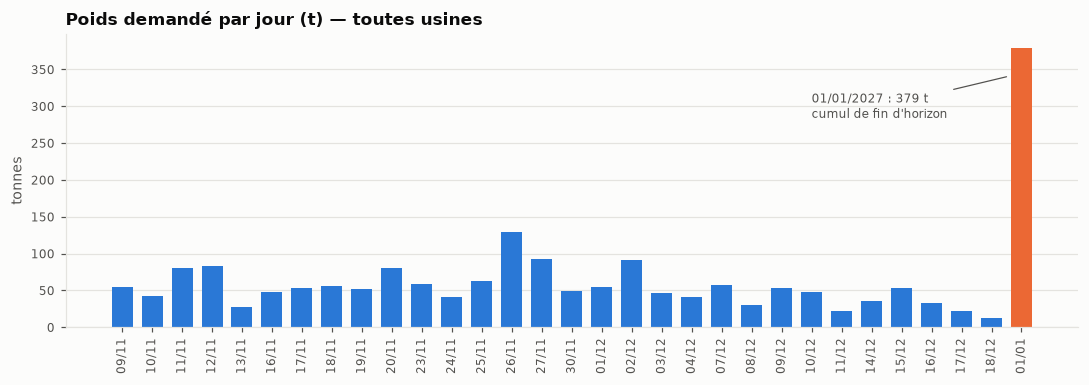

In [21]:
by_day = needs_raw.groupby("date")["weight"].sum() / 1000
last = by_day.index.max()
colors = [ACCENT if d >= pd.Timestamp(cfg.tail_date) else PRIMARY for d in by_day.index]

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(by_day.index.strftime("%d/%m"), by_day.values, color=colors, width=0.7)
ax.set_title("Poids demandé par jour (t) — toutes usines")
ax.set_ylabel("tonnes")
ax.tick_params(axis="x", rotation=90)
ax.annotate(f"{last:%d/%m/%Y} : {by_day[last]:.0f} t\ncumul de fin d'horizon",
            xy=(len(by_day) - 1.4, by_day[last] * 0.9), xytext=(len(by_day) - 8, by_day[last] * 0.75),
            fontsize=8, color=TEXT_MUTED, arrowprops=dict(arrowstyle="-", color=TEXT_MUTED, lw=0.8))
plt.tight_layout(); plt.show()

**On retire le 01/01/2027 de la consolidation.** Ce n'est pas un vrai jour de besoin : c'est la dernière date du programme, sur laquelle sont cumulées toutes les commandes prévues au-delà de l'horizon. Il pèse environ 7 fois un jour normal et tombe un jour férié, juste après les jours vides des fêtes. Le consolider fausserait les profils de livraison et les économies calculées.

**Distribution des besoins courants.** Pour lire la distribution des besoins réels, on enlève du tableau ci-dessous les lignes du 01/01 et les lignes dont le poids dépasse à lui seul la capacité d'un camion (24,5 t) : ces valeurs extrêmes écraseraient les statistiques.

In [22]:
truck_heavy = needs_raw["weight"] > cfg.truck_kg
before_tail = needs_raw["date"] < pd.Timestamp(cfg.tail_date)
courants = needs_raw[before_tail & ~truck_heavy]
print(f"Lignes retirées : {(~before_tail).sum()} à partir du {pd.Timestamp(cfg.tail_date):%d/%m/%Y} et "
      f"{(before_tail & truck_heavy).sum()} de plus de {cfg.truck_kg / 1000:.1f} t → {len(courants)} lignes restantes")
courants[["schedule_quantity", "weight", "volume"]].describe(percentiles=[.25, .5, .75, .95, .99]).T

Lignes retirées : 379 à partir du 01/01/2027 et 1 de plus de 24.5 t → 4389 lignes restantes


,count,mean,std,min,25%,50%,75%,95%,99%,max
schedule_quantity,4 389.00,1 351.81,3 821.37,1.00,132.00,400.00,1 000.00,5 000.00,16 000.00,100 000.00
weight,4 255.00,373.32,1 054.98,0.77,51.68,139.00,287.00,1 326.44,5 139.91,21 826.80
volume,4 273.00,0.66,0.60,0.01,0.07,0.57,1.14,1.20,2.88,5.81


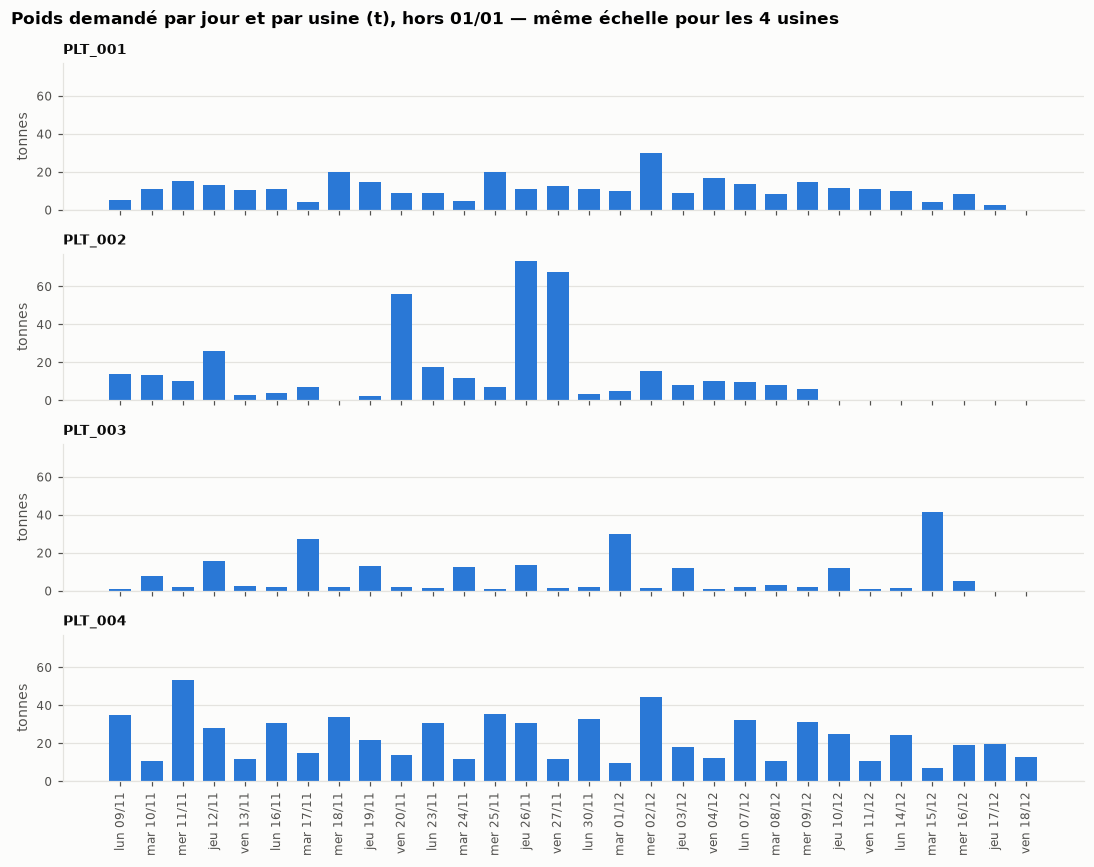

Jours avec au moins un besoin, sur 30 : {'PLT_001': 29, 'PLT_002': 23, 'PLT_003': 28, 'PLT_004': 30}


In [23]:
plants = sorted(needs_raw["plant"].unique())
per_plant = (needs_raw[needs_raw["date"] < pd.Timestamp(cfg.tail_date)]
             .pivot_table(index="date", columns="plant", values="weight", aggfunc="sum")
             .reindex(columns=plants).fillna(0) / 1000)
jours = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
labels = [f"{jours[d.weekday()]} {d:%d/%m}" for d in per_plant.index]

fig, axes = plt.subplots(len(plants), 1, figsize=(10, 8), sharex=True, sharey=True)
for ax, plant in zip(axes, plants):
    ax.bar(labels, per_plant[plant].values, color=PRIMARY, width=0.7)
    ax.set_title(plant, fontsize=9)
    ax.set_ylabel("tonnes")
axes[-1].tick_params(axis="x", rotation=90)
fig.suptitle("Poids demandé par jour et par usine (t), hors 01/01 — même échelle pour les 4 usines",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()
print("Jours avec au moins un besoin, sur", len(per_plant), ":", (per_plant > 0).sum().to_dict())

Chaque usine a son propre rythme :

- **PLT_004**, la plus chargée, a un besoin tous les jours, avec des pics le lundi et le mercredi (souvent plus de 30 t, jusqu'à 53 t le 11/11) et des creux le mardi et le vendredi (environ 10 à 15 t).
- **PLT_003** concentre ses besoins le mardi et le jeudi, avec un très gros mardi une semaine sur deux (27 t le 17/11, 30 t le 01/12, 41 t le 15/12).
- **PLT_002** est irrégulière : trois très gros jours (56 t le 20/11, 74 t le 26/11, 67 t le 27/11), puis plus aucun besoin à partir du 10/12.
- **PLT_001** a une charge régulière, presque tous les jours.

**Conséquence :** le lissage doit se faire **usine par usine**, en évitant d'ajouter des livraisons les jours déjà chargés (par exemple le lundi et le mercredi pour PLT_004).

## 4.3 `distances.csv`

In [24]:
sched_sup = schedule["supplier_id"].unique()
d_sched = distances[distances["supplier_id"].isin(sched_sup)]
print(f"{len(distances)} fournisseurs référencés, dont {len(d_sched)} présents dans le planning")
print(f"Distances manquantes : {distances['distance'].isna().sum()} au total, "
      f"dont {d_sched['distance'].isna().sum()} pour des fournisseurs du planning : "
      f"{', '.join(d_sched.loc[d_sched['distance'].isna(), 'supplier_id'])}")
print(f"Fournisseurs du planning absents du fichier : {len(set(sched_sup) - set(distances['supplier_id']))}")
d_sched["distance"].describe().to_frame("distance (km), fournisseurs du planning").T

156 fournisseurs référencés, dont 94 présents dans le planning
Distances manquantes : 11 au total, dont 2 pour des fournisseurs du planning : SUP_00047, SUP_00130
Fournisseurs du planning absents du fichier : 0


,count,mean,std,min,25%,50%,75%,max
"distance (km), fournisseurs du planning",92.00,62.91,35.50,6.00,33.00,60.50,82.25,149.00


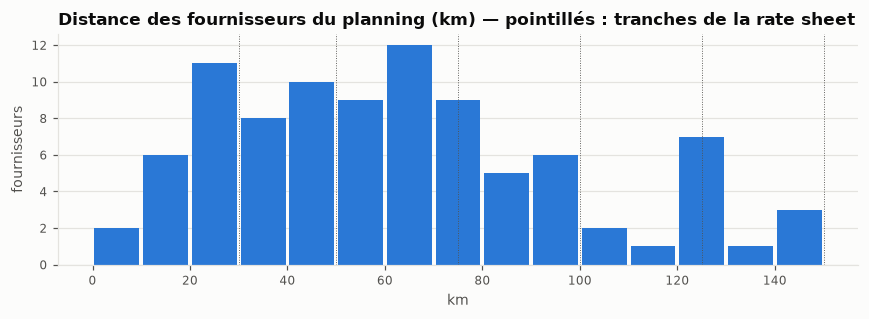

In [25]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(d_sched["distance"].dropna(), bins=range(0, 160, 10), color=PRIMARY, rwidth=0.92)
for b in [30, 50, 75, 100, 125, 150]:
    ax.axvline(b, color=TEXT_MUTED, lw=0.6, ls=":")
ax.set_title("Distance des fournisseurs du planning (km) — pointillés : tranches de la rate sheet")
ax.set_xlabel("km"); ax.set_ylabel("fournisseurs")
plt.tight_layout(); plt.show()

Tous les fournisseurs du planning sont à moins de 150 km : seules les 6 premières tranches de distance de la *rate sheet* serviront.

## 4.4 `rate_sheet.pdf` — la grille tarifaire

Le PDF est lu automatiquement (`load_rate_sheet`), et non recopié à la main. La grille est ensuite validée en recalculant l'exemple fourni dans le document.

In [26]:
grid = rate_sheet.grid.copy()
grid.index = [f"≤ {k:g}" if np.isfinite(k) else "> 650" for k in grid.index]
grid.columns = [f"≤ {k:g}" if np.isfinite(k) else "> 4000" for k in grid.columns]
grid.index.name, grid.columns.name = "km \\ kg", None
grid

,≤ 50,≤ 100,≤ 200,≤ 300,≤ 400,≤ 500,≤ 750,≤ 1000,≤ 1500,≤ 2000,≤ 2500,≤ 3000,≤ 3500,≤ 4000,> 4000
km \ kg,,,,,,,,,,,,,,,
≤ 30,4.75,6.66,8.56,10.73,13.06,14.75,17.75,22.35,25.67,31.40,35.08,35.16,37.73,40.87,42.42
≤ 50,5.78,7.94,10.74,13.07,15.45,17.35,20.96,25.32,30.05,35.97,40.52,42.90,47.04,51.05,52.80
≤ 75,6.92,9.54,13.14,15.99,18.43,20.59,24.96,29.02,35.52,41.70,47.33,52.58,57.55,62.30,64.28
≤ 100,7.33,10.27,14.35,17.61,20.40,22.88,27.96,32.63,40.20,47.30,53.77,59.79,65.47,70.89,73.04
≤ 125,7.77,10.99,15.57,19.24,22.37,25.17,30.95,36.25,44.89,52.91,60.21,66.99,73.38,79.47,81.80
≤ 150,8.26,11.83,17.04,21.23,24.84,28.09,34.86,41.01,51.20,60.59,69.12,77.06,84.54,91.65,94.22
≤ 175,9.85,14.04,19.96,24.65,28.69,32.28,39.74,46.45,57.51,68.25,78.04,87.13,95.69,103.83,106.65
≤ 200,11.45,16.31,23.21,28.67,33.33,37.49,46.16,53.90,66.69,78.23,88.63,98.88,108.54,117.72,120.80
≤ 250,13.56,19.66,28.43,35.44,41.45,46.84,58.22,68.33,85.24,100.38,114.05,126.66,138.46,149.64,153.36


**Fonction `prix` et vérification sur l'exemple du PDF.** Le prix d'un envoi se lit dans la grille par tranche supérieure (bornes hautes incluses),
puis `prix = coût de base × (1 + marge) × surcharge diesel` (RG11). Le calcul est vérifié sur l'exemple fourni dans le PDF :
300 km, 1 000 kg → 82,77 € → 280,78 € → **335,34 €**.

In [27]:
def base_cost(sheet: RateSheet, distance_km: float, weight_kg: float) -> float:
    """Base cost of one shipment: row = smallest km bound >= distance, column = smallest kg bound >= weight."""
    km = brackets(sheet.grid.index, [distance_km])[0]
    kg = brackets(sheet.grid.columns, [weight_kg])[0]
    return float(sheet.grid.loc[km, kg])


def prix(sheet: RateSheet, distance_km: float, weight_kg: float) -> float:
    """Price of one shipment (RG11): base cost x (1 + margin) x diesel surcharge."""
    return base_cost(sheet, distance_km, weight_kg) * (1 + sheet.margin) * sheet.diesel_surcharge


example_base = base_cost(rate_sheet, 300, 1000)
example_price = round(prix(rate_sheet, 300, 1000), 2)
assert example_base == 82.77, example_base
assert example_price == 335.34, example_price
logger.info("PDF example reproduced: base %.2f EUR -> price %.2f EUR", example_base, example_price)
pd.Series({"coût de base (300 km, 1 000 kg)": example_base, "prix final": example_price}, name="EUR").to_frame()

,EUR
"coût de base (300 km, 1 000 kg)",82.77
prix final,335.34


## 4.5 Où se situent les livraisons actuelles dans la grille tarifaire ?

On croise les trois sources : chaque livraison actuelle (couple × jour) est placée dans la grille selon la distance de son fournisseur et son poids.

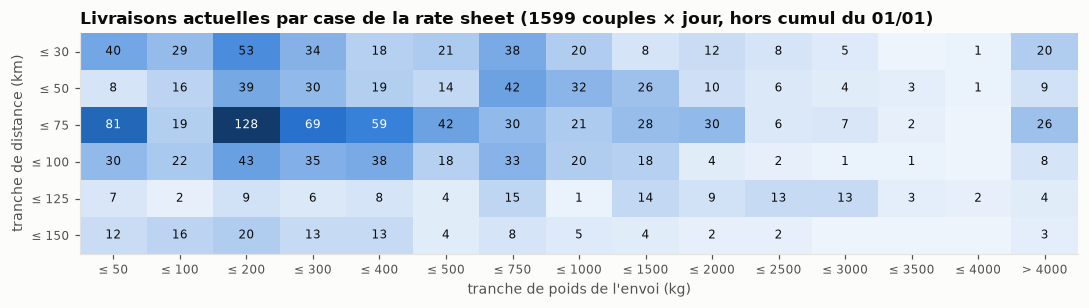

Livraisons ≤ 1 000 kg : 80%   |   > 4 000 kg : 4%


In [28]:
from matplotlib.colors import LinearSegmentedColormap

cur = (needs_raw.merge(distances, on="supplier_id", how="left")
       .groupby(list(cfg.couple_key) + ["date"]).agg(weight=("weight", "sum"), distance=("distance", "first"))
       .reset_index())
cur = cur[(cur["date"] < pd.Timestamp(cfg.tail_date)) & cur["distance"].notna() & (cur["weight"] > 0)]
cur["km"] = brackets(rate_sheet.grid.index, cur["distance"])
cur["kg"] = brackets(rate_sheet.grid.columns, cur["weight"])
mat = pd.crosstab(cur["km"], cur["kg"]).reindex(columns=rate_sheet.grid.columns, fill_value=0)

cmap = LinearSegmentedColormap.from_list("seq", ["#eef4fc", PRIMARY, "#123a6b"])
fig, ax = plt.subplots(figsize=(10, 2.9))
ax.imshow(mat.values, cmap=cmap, aspect="auto")
ax.set_xticks(range(mat.shape[1]), [f"≤ {c:g}" if np.isfinite(c) else "> 4000" for c in mat.columns])
ax.set_yticks(range(mat.shape[0]), [f"≤ {k:g}" for k in mat.index])
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        v = mat.values[i, j]
        if v:
            ax.text(j, i, v, ha="center", va="center", fontsize=8,
                    color="white" if v > mat.values.max() * 0.45 else TEXT)
ax.grid(False)
ax.set_xlabel("tranche de poids de l'envoi (kg)"); ax.set_ylabel("tranche de distance (km)")
ax.set_title(f"Livraisons actuelles par case de la rate sheet ({len(cur)} couples × jour, hors cumul du 01/01)")
plt.tight_layout(); plt.show()

print(f"Livraisons ≤ 1 000 kg : {(cur['weight'] <= 1000).mean():.0%}   |   > 4 000 kg : {(cur['weight'] > 4000).mean():.0%}")

## 4.6 Valeurs manquantes ou nulles

**Règle :** sur une ligne avec besoin, un poids ou un volume **à 0 est traité exactement comme une valeur manquante**. Les deux ont le même impact : on ne connaît pas la charge réelle de la ligne. Ils sont donc comptés ensemble (`is_missing`) et complétés par la même règle (Partie 5, DQ04).

In [29]:
pd.concat({
    "schedule (quantité > 0)": missing_values(needs_raw),
    "distances": missing_values(distances),
})

vides  nuls  manquants_ou_nuls  pct
schedule (quantité > 0) weight      139     0                139 2.91
                        volume      119     0                119 2.50
distances               distance     11     0                 11 7.05

In [30]:
w_miss, v_miss = is_missing(needs_raw["weight"]), is_missing(needs_raw["volume"])
miss = needs_raw[w_miss | v_miss]
before_tail_miss = needs_raw["date"] < pd.Timestamp(cfg.tail_date)
print(f"{len(miss)} lignes avec besoin ont un poids ou un volume manquant ou nul ; "
      f"{(w_miss & v_miss).sum()} n'ont ni l'un ni l'autre (le {pd.Timestamp(cfg.tail_date):%d/%m/%Y} est inclus ; "
      f"hors cette date : {int(w_miss[before_tail_miss].sum())} poids et {int(v_miss[before_tail_miss].sum())} volumes manquants).")
has_weight_elsewhere = miss["material"].isin(needs_raw.loc[~w_miss, "material"])
print(f"Seules {has_weight_elsewhere[w_miss[miss.index]].sum()} lignes à poids manquant ou nul concernent un material "
      f"dont le poids est connu ailleurs dans le planning → un repli au-delà du material est nécessaire.")
miss.groupby(list(cfg.couple_key)).size().sort_values(ascending=False).head(8).rename("lignes incomplètes").to_frame()

139 lignes avec besoin ont un poids ou un volume manquant ou nul ; 119 n'ont ni l'un ni l'autre (le 01/01/2027 est inclus ; hors cette date : 134 poids et 116 volumes manquants).
Seules 21 lignes à poids manquant ou nul concernent un material dont le poids est connu ailleurs dans le planning → un repli au-delà du material est nécessaire.


lignes incomplètes
supplier_id plant                      
SUP_00129   PLT_003                  24
            PLT_001                  19
SUP_00001   PLT_004                  17
SUP_00117   PLT_002                  12
SUP_00153   PLT_004                  11
SUP_00046   PLT_002                   6
SUP_00107   PLT_002                   5
SUP_00145   PLT_002                   5

Les valeurs manquantes sont **concentrées sur quelques couples** : SUP_00129 en représente à lui seul près d'un tiers (43 lignes sur 139, le 01/01 étant inclus). Il ne s'agit donc pas d'un bruit aléatoire mais de *materials* dont la fiche logistique n'est pas renseignée. C'est un point à remonter au métier.

---

# Partie 5 - Préparation et nettoyage des données

*Source : `preparation.ipynb`*

## Préparation et nettoyage des données

**But :** transformer les trois sources brutes (`released_schedule.csv`, `distances.csv`, `rate_sheet.csv`)
en entrées propres et fiables pour la consolidation. Chaque cas trouvé dans la Partie 4
reçoit une règle de nettoyage explicite, un identifiant et une ligne dans le **registre des anomalies** (EF02).
Chaque imputation est tracée dans une colonne dédiée (EF03).

Colonnes ignorées : `transmission_date`, `version_date` (non utilisées, voir 3.2).

| ID | Source | Cas | Détection | Règle de nettoyage | Statut |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **DQ01** | planning | Quantité = 0, négative ou vide | `schedule_quantity <= 0` ou NaN | Supprimer la ligne : 0 signifie « pas de besoin », négatif / vide n'ont pas de sens | Appliqué |
| **DQ02** | planning | Date hors horizon, en week-end ou un jour férié allemand | Comparaison avec l'horizon, `day_of_week`, calendrier des jours fériés (`holidays`) | Signaler et conserver : on ne reçoit rien le week-end ni les jours fériés, mais la ligne reste et l'optimisation la prend en compte | Appliqué |
| **DQ03** | planning | Dates >= 01/01/2027 = besoins cumulés après l'horizon journalier (jour férié) | `date >= tail_date` | Supprimer ces lignes (date de coupure réglable via `tail_date`) | Appliqué |
| **DQ04** | planning | Poids / volume manquant ou à 0 avec quantité > 0 | `isna()` ou `<= 0` | Remplacer par la capacité d'un camion (`truck_kg`, `truck_m3`) ou, selon le paramètre `impute_quantile`, par un quantile du couple puis de l'usine ; marquer `*_imputed` et `*_impute_level` | Appliqué |
| **DQ05** | planning | Ligne dont le poids dépasse la capacité d'un camion (24,5 t) | `weight > truck_kg` | Supprimer la ligne (capacité réglable via `truck_kg`) ; limite connue, voir RG08 | Appliqué |
| **DQ06** | distances | Fournisseur en double | `duplicated("supplier_id")` | Garder la première valeur, signaler le reste | Appliqué |
| **DQ07** | distances | Fournisseur sans distance, absent du fichier ou distance <= 0 | `isna()`, jointure gauche, `<= 0` | Médiane des distances des fournisseurs présents dans le planning ; marquer `distance_imputed` | Appliqué |

Les paramètres sont regroupés à un seul endroit (`CleaningConfig`, EF12) pour pouvoir les changer sans toucher à la logique.

In [31]:
from __future__ import annotations

import logging

import numpy as np
import pandas as pd

logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s %(levelname)-7s %(message)s",
    datefmt="%H:%M:%S",
    force=True,
)
logger = logging.getLogger("preparation")


logger.info("Configuration: %s", cfg)

17:21:37 INFO    Configuration: CleaningConfig(data_dir=WindowsPath('../docs'), output_dir=WindowsPath('../data'), truck_kg=24500.0, truck_m3=110.4, horizon_start='2026-11-09', horizon_end='2027-01-01', holiday_country='DE', holiday_subdiv=None, tail_date='2027-01-01', impute_quantile=None, max_anticipation_days=7, allowed_frequencies=(1, 2, 3, 4, 5), couple_key=('supplier_id', 'plant'), key_columns=('date', 'supplier_id', 'material', 'plant', 'unloading_point'))


## 5.1 Registre des anomalies (EF02)

Chaque règle ci-dessous appelle `register(...)` : source, identifiant de la règle, gravité, nombre de lignes et action prise.
Le registre est exporté à la fin.

In [32]:
ANOMALIES: list[dict[str, object]] = []


def register(rule: str, source: str, severity: str, n_rows: int, action: str) -> None:
    """Record one finding in the register and log it with the matching level."""
    ANOMALIES.append(
        {
            "rule": rule,
            "source": source,
            "severity": severity if n_rows else "none",
            "rows": int(n_rows),
            "action": action,
        }
    )
    level = logging.WARNING if n_rows and severity != "info" else logging.INFO
    logger.log(level, "%s [%s] %d row(s) - %s", rule, source, n_rows, action)

## 5.2 Chargement des sources brutes

In [33]:
schedule_raw = pd.read_csv(
    cfg.data_dir / "released_schedule.csv", encoding="utf-8-sig", parse_dates=["date"]
).drop(columns=["transmission_date", "version_date"])
distances_raw = pd.read_csv(cfg.data_dir / "distances.csv", encoding="utf-8-sig")

logger.info("released_schedule: %s", schedule_raw.shape)
logger.info("distances: %s", distances_raw.shape)

schedule = schedule_raw.copy()
schedule_raw.head()

17:21:37 INFO    released_schedule: (5728, 8)


17:21:37 INFO    distances: (156, 2)


,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume
0,2026-11-10,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.00,0.00,0.41
1,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41
2,2026-11-12,SUP_00091,MAT_000110,PLT_004,ULP_0050,0.00,0.00,0.41
3,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41
4,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41


## 5.3 Quantités et calendrier

### DQ01 - Quantité = 0, négative ou vide
**Règle :** ne garder que les lignes avec `schedule_quantity > 0`.
**Pourquoi :** 0 signifie « pas de besoin » (voir la Partie 3, dictionnaire), il n'y a donc rien à transporter. Une quantité négative ou vide
n'a pas de sens métier. Ces lignes sont comptées par type avant d'être supprimées.

### DQ02 - Date hors horizon, en week-end ou un jour férié allemand
**Règle :** signaler et **conserver** la ligne.
**Pourquoi :** on ne reçoit rien le week-end ni les jours fériés allemands, mais un besoin daté ces jours-là reste un vrai besoin :
l'optimisation le prend en compte (il sera livré un jour ouvré précédent, RG10). Une date hors de l'horizon 09/11/2026 - 01/01/2027 est seulement signalée.
Les jours fériés viennent du paquet `holidays` (Allemagne, niveau national par défaut ; une région se règle avec `holiday_subdiv`).
Sur l'horizon, ce sont le 25/12 et le 26/12 (et le 01/01, retiré par DQ03).

In [34]:
qty = schedule["schedule_quantity"]
register("DQ01", "schedule", "info", int((qty == 0).sum()), "dropped (quantity = 0, no need)")
register("DQ01", "schedule", "error", int((qty < 0).sum()), "dropped (negative quantity)")
register("DQ01", "schedule", "error", int(qty.isna().sum()), "dropped (missing quantity)")
schedule = schedule.loc[qty > 0].copy()

outside = ~schedule["date"].between(cfg.horizon_start, cfg.horizon_end)
weekend = schedule["date"].dt.day_of_week >= 5
register("DQ02", "schedule", "warning", int(outside.sum()), "flagged and kept (outside horizon)")
register("DQ02", "schedule", "warning", int(weekend.sum()), "flagged and kept (no delivery on weekends, handled by the optimization)")

# german_holidays comes from the shared configuration cell
# Rows on tail_date and after are removed by DQ03: do not report them here
on_holiday = schedule["date"].dt.date.isin(list(german_holidays)) & (
    schedule["date"] < pd.Timestamp(cfg.tail_date)
)
register(
    "DQ02",
    "schedule",
    "warning",
    int(on_holiday.sum()),
    "flagged and kept (no delivery on German public holidays, handled by the optimization)",
)
logger.info("Rows with a need: %d", len(schedule))

17:21:37 INFO    DQ01 [schedule] 959 row(s) - dropped (quantity = 0, no need)


17:21:37 INFO    DQ01 [schedule] 0 row(s) - dropped (negative quantity)


17:21:37 INFO    DQ01 [schedule] 0 row(s) - dropped (missing quantity)


17:21:37 INFO    DQ02 [schedule] 0 row(s) - flagged and kept (outside horizon)


17:21:37 INFO    DQ02 [schedule] 0 row(s) - flagged and kept (no delivery on weekends, handled by the optimization)


17:21:37 INFO    DQ02 [schedule] 0 row(s) - flagged and kept (no delivery on German public holidays, handled by the optimization)


17:21:37 INFO    Rows with a need: 4769


### DQ03 - Dates >= 01/01/2027
**Règle :** supprimer toutes les lignes dont la date est supérieure ou égale à `tail_date` (01/01/2027 par défaut).
La date de coupure se règle dans `CleaningConfig` ; le nombre de lignes retirées est tracé dans le registre.
**Pourquoi :** c'est un jour férié et il regroupe les besoins *après* l'horizon journalier (quantités plusieurs fois supérieures
à un jour normal, 55 materials jamais vus avant). Le garder fausserait le remplissage et le lissage.
**Alternative :** repousser `tail_date` (par exemple `2027-01-02`) pour le garder comme un jour normal, cohérent avec les chiffres du cours (1 731 livraisons).

In [35]:
is_tail = schedule["date"] >= pd.Timestamp(cfg.tail_date)
register(
    "DQ03",
    "schedule",
    "info",
    int(is_tail.sum()),
    f"dropped (date >= {cfg.tail_date}, needs accumulated after the horizon)",
)
schedule = schedule.loc[~is_tail].copy()
logger.info("Rows kept after DQ03: %d", len(schedule))

17:21:37 INFO    DQ03 [schedule] 379 row(s) - dropped (date >= 2027-01-01, needs accumulated after the horizon)


17:21:37 INFO    Rows kept after DQ03: 4390


## 5.4 Poids et volume

### DQ04 - Poids / volume manquant ou à 0
**Règle :** sur une ligne avec `quantity > 0`, un poids ou un volume manquant ou à 0 est imputé selon le paramètre `impute_quantile` de `CleaningConfig` :

| `impute_quantile` | Valeur imputée |
| :--- | :--- |
| `None` (défaut) | la **capacité d'un camion** : `truck_kg` (24 500 kg) et `truck_m3` (110,4 m³), choix le plus prudent |
| un nombre entre 0 et 1 (par exemple `0.95`) | ce **quantile** des valeurs valides (`> 0`) du **même couple fournisseur × usine**, sinon de la **même usine** (`0.5` = médiane) |

Chaque valeur imputée est tracée dans `weight_imputed` / `volume_imputed` et `*_impute_level` (`truck_max`, `couple` ou `plant`, EF03).

**Pourquoi :** supprimer la ligne ferait oublier un vrai besoin, et une règle de trois sur la quantité n'est pas fiable (le poids est une partie
fixe d'emballage plus une partie par pièce). On préfère surestimer la charge d'une ligne inconnue plutôt que la sous-estimer.

**Conséquence du défaut :** une ligne imputée remplit un camion à elle seule, elle pèse donc beaucoup dans l'indicateur de précision (5.6).
Un quantile plus bas (0,95 par exemple) donne une charge plus réaliste : le paramètre permet de comparer les deux choix.

In [36]:
def impute_missing(df: pd.DataFrame, column: str, capacity: float, quantile: float | None) -> pd.DataFrame:
    """Fill missing or non-positive values of `column`.

    quantile None: the truck capacity. Otherwise the quantile of the valid values of the same couple,
    then of the same plant, and the truck capacity if neither exists.
    """
    result = df.copy()
    needs = result[column].isna() | (result[column] <= 0)
    level = pd.Series(pd.NA, index=result.index, dtype="string")

    if quantile is None:
        result.loc[needs, column] = capacity
        level[needs] = "truck_max"
        counts = {"truck_max": int(needs.sum())}
    else:
        reference = result[column].where(result[column] > 0)

        def group_quantile(keys: list[str]) -> pd.Series:
            return reference.groupby([result[k] for k in keys]).transform(lambda s: s.quantile(quantile))

        by_couple = needs & group_quantile(list(cfg.couple_key)).notna()
        by_plant = needs & ~by_couple & group_quantile(["plant"]).notna()
        fallback = needs & ~by_couple & ~by_plant
        result.loc[by_couple, column] = group_quantile(list(cfg.couple_key))[by_couple]
        result.loc[by_plant, column] = group_quantile(["plant"])[by_plant]
        result.loc[fallback, column] = capacity
        level[by_couple], level[by_plant], level[fallback] = "couple", "plant", "truck_max"
        counts = {"couple": int(by_couple.sum()), "plant": int(by_plant.sum()), "truck_max": int(fallback.sum())}

    result[f"{column}_imputed"] = needs
    result[f"{column}_impute_level"] = level
    for name, n_rows in counts.items():
        register("DQ04", "schedule", "warning", n_rows, f"{column} imputed ({name}, impute_quantile={quantile})")
    return result


schedule = impute_missing(schedule, "weight", cfg.truck_kg, cfg.impute_quantile)
schedule = impute_missing(schedule, "volume", cfg.truck_m3, cfg.impute_quantile)

schedule[schedule["weight_imputed"] | schedule["volume_imputed"]].head()

17:21:37 WARNING DQ04 [schedule] 134 row(s) - weight imputed (truck_max, impute_quantile=None)


17:21:37 WARNING DQ04 [schedule] 116 row(s) - volume imputed (truck_max, impute_quantile=None)


,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,weight_imputed,weight_impute_level,volume_imputed,volume_impute_level
1755,2026-11-10,SUP_00112,MAT_000611,PLT_004,ULP_0017,18.00,24 500.00,110.40,True,truck_max,True,truck_max
2120,2026-11-09,SUP_00109,MAT_000522,PLT_002,ULP_0025,271.00,24 500.00,110.40,True,truck_max,True,truck_max
2178,2026-12-08,SUP_00133,MAT_001031,PLT_002,ULP_0022,32.00,24 500.00,110.40,True,truck_max,True,truck_max
2354,2026-11-09,SUP_00117,MAT_000613,PLT_002,ULP_0022,30.00,24 500.00,110.40,True,truck_max,True,truck_max
2355,2026-11-10,SUP_00117,MAT_000613,PLT_002,ULP_0022,30.00,24 500.00,110.40,True,truck_max,True,truck_max


### DQ05 - Ligne plus lourde qu'un camion
**Règle :** supprimer toute ligne dont le poids dépasse `truck_kg` (24 500 kg par défaut).
**Pourquoi :** le poids d'une ligne est celui d'un seul jour de besoin ; au-delà de la capacité d'un camion, la ligne ne tient pas dans
une livraison (RG04) et on choisit de ne pas la traiter. La règle passe après l'imputation (DQ04) : avec le défaut, un poids imputé vaut exactement `truck_kg` et n'est donc jamais retiré ici.
Les lignes retirées sont comptées dans `rows_removed` de l'indicateur de précision.

**Limite connue :** cette ligne (SUP_00074, 26,9 t) est un vrai besoin qui ne sera pas livré, ce qui déroge à RG08 (quantité livrée = quantité demandée). Elle est listée ci-dessous et dans le registre pour être traitée à part (plusieurs camions ou décision métier).

In [37]:
overweight = schedule["weight"] > cfg.truck_kg
overweight_rows = schedule.loc[
    overweight, ["date", "supplier_id", "material", "plant", "schedule_quantity", "weight"]
]
register(
    "DQ05",
    "schedule",
    "warning",
    int(overweight.sum()),
    f"dropped (weight > {cfg.truck_kg:.0f} kg, heavier than one truck)",
)
schedule = schedule.loc[~overweight].copy()
overweight_rows

17:21:37 WARNING DQ05 [schedule] 1 row(s) - dropped (weight > 24500 kg, heavier than one truck)


,date,supplier_id,material,plant,schedule_quantity,weight
5015,2026-12-15,SUP_00074,MAT_001164,PLT_003,5 670.00,26 905.20


## 5.5 Distances

### DQ06 - Fournisseur en double
**Règle :** garder la première valeur et signaler le reste. **Pourquoi :** un fournisseur n'a qu'une distance.

### DQ07 - Distance manquante
**Règle :** une distance vide, absente de `distances.csv` ou `<= 0` est remplacée par la **médiane des distances des
fournisseurs présents dans le planning** (60,5 km, voir la Partie 4) et marquée `distance_imputed = True`.
**Pourquoi :** après DQ03, un seul fournisseur est concerné (SUP_00130, 4 lignes ; SUP_00047 n'apparaissait que le 01/01).
Garder ses besoins dans la consolidation coûte moins de précision que de les retirer.
**Alternative (option B) :** exclure ces fournisseurs du calcul de coût.

In [38]:
n_dup_suppliers = int(distances_raw["supplier_id"].duplicated().sum())
register("DQ06", "distances", "warning", n_dup_suppliers, "kept first value")
distances = distances_raw.drop_duplicates("supplier_id", keep="first").copy()
distances["distance"] = pd.to_numeric(distances["distance"], errors="coerce")
distances.loc[distances["distance"] <= 0, "distance"] = np.nan

planning_suppliers = pd.DataFrame({"supplier_id": sorted(schedule["supplier_id"].unique())})
supplier_distance = planning_suppliers.merge(distances, on="supplier_id", how="left")
fallback_distance = float(supplier_distance["distance"].median())

supplier_distance["distance_imputed"] = supplier_distance["distance"].isna()
supplier_distance["distance"] = supplier_distance["distance"].fillna(fallback_distance)

missing_suppliers = supplier_distance.loc[supplier_distance["distance_imputed"], "supplier_id"]
register(
    "DQ07",
    "distances",
    "warning",
    len(missing_suppliers),
    f"{len(missing_suppliers)} supplier(s) imputed with the median {fallback_distance} km",
)

schedule = schedule.merge(supplier_distance, on="supplier_id", how="left", validate="m:1")
logger.info("Fallback distance: %s km, suppliers: %s", fallback_distance, list(missing_suppliers))
supplier_distance[supplier_distance["distance_imputed"]]

17:21:37 INFO    DQ06 [distances] 0 row(s) - kept first value


17:21:37 WARNING DQ07 [distances] 1 row(s) - 1 supplier(s) imputed with the median 60.5 km


17:21:37 INFO    Fallback distance: 60.5 km, suppliers: ['SUP_00130']


,supplier_id,distance,distance_imputed
76,SUP_00130,60.50,True


## 5.6 Indicateur de précision des données (accuracy)

Toutes les modifications faites ci-dessus sont comptées dans la précision de l'optimisation : plus une part
des résultats repose sur des valeurs imputées, moins ils sont fiables.

| Indicateur | Définition |
| :--- | :--- |
| `rows_removed` | Lignes brutes retirées du périmètre (DQ01, DQ03 et DQ05) |
| `rows_modified` | Lignes avec au moins une valeur imputée : poids, volume (DQ04) ou distance du fournisseur (DQ07) |
| `rows_accuracy` | 1 - `rows_modified` / `rows` : part des lignes entièrement d'origine |
| `weight_accuracy` | Part du poids total qui vient de valeurs d'origine (non imputées) |
| `volume_accuracy` | Part du volume total qui vient de valeurs d'origine (non imputées) |

Les mêmes indicateurs sont calculés globalement, par usine et par couple fournisseur × usine (unité de l'optimisation).

In [39]:
def accuracy(df: pd.DataFrame) -> pd.Series:
    """Share of original (non-imputed) rows and weight in `df`."""
    modified = df["weight_imputed"] | df["volume_imputed"] | df["distance_imputed"]
    original_weight = df["weight"].where(~df["weight_imputed"], 0.0)
    original_volume = df["volume"].where(~df["volume_imputed"], 0.0)
    return pd.Series(
        {
            "rows": len(df),
            "rows_modified": int(modified.sum()),
            "rows_accuracy": 1 - float(modified.mean()),
            "weight_accuracy": float(original_weight.sum() / df["weight"].sum()),
            "volume_accuracy": float(original_volume.sum() / df["volume"].sum()),
        }
    )


accuracy_global = accuracy(schedule)
accuracy_global["rows_removed"] = len(schedule_raw) - len(schedule)
accuracy_by_plant = pd.DataFrame({k: accuracy(g) for k, g in schedule.groupby("plant")}).T
accuracy_by_couple = pd.DataFrame(
    {k: accuracy(g) for k, g in schedule.groupby(["supplier_id", "plant"])}
).T
accuracy_by_couple.index.names = ["supplier_id", "plant"]

logger.info(
    "Accuracy: rows %.1f%% | weight %.1f%% | volume %.1f%% | %d row(s) modified, %d removed",
    100 * accuracy_global["rows_accuracy"],
    100 * accuracy_global["weight_accuracy"],
    100 * accuracy_global["volume_accuracy"],
    accuracy_global["rows_modified"],
    accuracy_global["rows_removed"],
)
accuracy_by_plant.round(4)

17:21:37 INFO    Accuracy: rows 96.9% | weight 32.6% | volume 18.0% | 138 row(s) modified, 1339 removed


,rows,rows_modified,rows_accuracy,weight_accuracy,volume_accuracy
PLT_001,1 183.00,25.00,0.98,0.36,0.15
PLT_002,1 419.00,55.00,0.96,0.23,0.14
PLT_003,448.00,28.00,0.94,0.22,0.06
PLT_004,1 339.00,30.00,0.98,0.48,0.44


## 5.7 Résultat et export
Le dossier `data` ne contient que : `consolidated_dataset.csv` (5.8), `anomaly_register.csv` et les trois tableaux de précision (`accuracy_*.csv`).

In [40]:
schedule_clean = schedule
anomaly_register = pd.DataFrame(ANOMALIES)

assert schedule_clean[["weight", "volume", "distance"]].notna().all().all()
assert (schedule_clean["schedule_quantity"] > 0).all()
assert not schedule_clean.duplicated(list(cfg.key_columns)).any()

logger.info("Raw: %d rows -> clean: %d rows", len(schedule_raw), len(schedule_clean))

cfg.output_dir.mkdir(parents=True, exist_ok=True)
anomaly_register.to_csv(cfg.output_dir / "anomaly_register.csv", index=False)
accuracy_global.to_frame("value").to_csv(cfg.output_dir / "accuracy_global.csv")
accuracy_by_plant.to_csv(cfg.output_dir / "accuracy_by_plant.csv")
accuracy_by_couple.to_csv(cfg.output_dir / "accuracy_by_couple.csv")
logger.info("Registry and accuracy files written to %s", cfg.output_dir.resolve())

anomaly_register

17:21:37 INFO    Raw: 5728 rows -> clean: 4389 rows


17:21:37 INFO    Registry and accuracy files written to C:\Users\houeg\projects\delivery_schedule_optimization\data


,rule,source,severity,rows,action
0,DQ01,schedule,info,959,"dropped (quantity = 0, no need)"
1,DQ01,schedule,none,0,dropped (negative quantity)
2,DQ01,schedule,none,0,dropped (missing quantity)
3,DQ02,schedule,none,0,flagged and kept (outside horizon)
4,DQ02,schedule,none,0,"flagged and kept (no delivery on weekends, handled by the optimization)"
5,DQ02,schedule,none,0,"flagged and kept (no delivery on German public holidays, handled by the optimization)"
6,DQ03,schedule,info,379,"dropped (date >= 2027-01-01, needs accumulated after the horizon)"
7,DQ04,schedule,warning,134,"weight imputed (truck_max, impute_quantile=None)"
8,DQ04,schedule,warning,116,"volume imputed (truck_max, impute_quantile=None)"
9,DQ05,schedule,warning,1,"dropped (weight > 24500 kg, heavier than one truck)"


## 5.8 Jeu de données consolidé : jointure avec les distances

Le jeu de données final rassemble, **ligne par ligne**, le besoin nettoyé et la distance de son fournisseur.
La jointure est de type *plusieurs lignes → une seule* (`validate="m:1"`) :

| Jointure | Clé | Apporte |
| :--- | :--- | :--- |
| planning nettoyé ↔ distances | `supplier_id` | `distance` (faite en DQ07, une distance par fournisseur) |

La grille tarifaire n'est **pas** jointe ici : le coût dépend du poids total d'un camion, qui n'existe qu'après le regroupement
des besoins en camions (jalon 3).

Contrôles : aucune ligne perdue ni dupliquée, aucune jointure sans correspondance.
Le fichier final ne garde que l'utile : identité de la ligne, quantité, poids, volume et `distance`.

In [41]:
# Join: distance per supplier (already attached in DQ07), checked on the supplier key
consolidated = schedule_clean.drop(columns=["distance", "distance_imputed"]).merge(
    supplier_distance, on="supplier_id", how="left", validate="m:1"
)

# Checks: no lost / duplicated line, no join without match
assert len(consolidated) == len(schedule_clean), "the join changed the number of rows"
assert not consolidated.duplicated(list(cfg.key_columns)).any(), "duplicated line key"
assert consolidated["distance"].notna().all(), "supplier without distance"

# Keep only what the optimization needs: line identity, load and distance
consolidated = consolidated[[*cfg.key_columns, "schedule_quantity", "weight", "volume", "distance"]]
logger.info("Consolidated dataset: %d rows x %d columns", *consolidated.shape)

consolidated.to_csv(cfg.output_dir / "consolidated_dataset.csv", index=False)
logger.info("File written: consolidated_dataset.csv")

consolidated.head()

17:21:37 INFO    Consolidated dataset: 4389 rows x 9 columns


17:21:37 INFO    File written: consolidated_dataset.csv


,date,supplier_id,material,plant,unloading_point,schedule_quantity,weight,volume,distance
0,2026-11-11,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
1,2026-11-13,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
2,2026-11-16,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
3,2026-11-18,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00
4,2026-11-19,SUP_00091,MAT_000110,PLT_004,ULP_0050,5 000.00,92.60,0.41,22.00


## 5.9 Dictionnaire du jeu consolidé

Description de chaque colonne de `consolidated_dataset.csv` (le fichier lu par l'optimisation), avec les valeurs manquantes et les bornes constatées.

In [42]:
output_dictionary = pd.DataFrame(
    [
        ("date", "jour", "Jour où la pièce doit être à l'usine", "released_schedule.csv"),
        ("supplier_id", "–", "Fournisseur (clé vers les distances)", "released_schedule.csv"),
        ("material", "–", "Référence de la pièce", "released_schedule.csv"),
        ("plant", "–", "Usine de destination ; avec le fournisseur, forme le couple", "released_schedule.csv"),
        ("unloading_point", "–", "Quai de déchargement", "released_schedule.csv"),
        ("schedule_quantity", "pièces", "Pièces à livrer (toujours > 0)", "released_schedule.csv"),
        ("weight", "kg", "Poids de la ligne, emballage compris (imputé si manquant, DQ04)", "released_schedule.csv + DQ04"),
        ("volume", "m³", "Volume du conteneur de la ligne (imputé si manquant, DQ04)", "released_schedule.csv + DQ04"),
        ("distance", "km", "Distance du fournisseur au point de consolidation (imputée si manquante, DQ07)", "distances.csv + DQ07"),
    ],
    columns=["colonne", "unité", "description", "origine"],
).set_index("colonne")
output_dictionary["type"] = consolidated.dtypes.astype(str)
output_dictionary["manquants"] = consolidated.isna().sum()
output_dictionary["min"] = consolidated.min(numeric_only=False).map(lambda v: f"{v:%d/%m/%Y}" if isinstance(v, pd.Timestamp) else v)
output_dictionary["max"] = consolidated.max(numeric_only=False).map(lambda v: f"{v:%d/%m/%Y}" if isinstance(v, pd.Timestamp) else v)
output_dictionary

,unité,description,origine,type,manquants,min,max
colonne,,,,,,,
date,jour,Jour où la pièce doit être à l'usine,released_schedule.csv,datetime64[us],0,09/11/2026,18/12/2026
supplier_id,–,Fournisseur (clé vers les distances),released_schedule.csv,str,0,SUP_00001,SUP_00156
material,–,Référence de la pièce,released_schedule.csv,str,0,MAT_000001,MAT_001229
plant,–,"Usine de destination ; avec le fournisseur, forme le couple",released_schedule.csv,str,0,PLT_001,PLT_004
unloading_point,–,Quai de déchargement,released_schedule.csv,str,0,ULP_0001,ULP_0050
schedule_quantity,pièces,Pièces à livrer (toujours > 0),released_schedule.csv,float64,0,1.00,100 000.00
weight,kg,"Poids de la ligne, emballage compris (imputé si manquant, DQ04)",released_schedule.csv + DQ04,float64,0,0.77,24 500.00
volume,m³,"Volume du conteneur de la ligne (imputé si manquant, DQ04)",released_schedule.csv + DQ04,float64,0,0.01,110.40
distance,km,"Distance du fournisseur au point de consolidation (imputée si manquante, DQ07)",distances.csv + DQ07,float64,0,6.00,149.00
